Saving archive (5) (1).csv to archive (5) (1) (2).csv
Dataset loaded successfully!
Shape: (418, 12)

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S



Preprocessed Dataset:


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,34.5,0,0,7.8292,True,True,False
1,1,3,47.0,1,0,7.0000,False,False,True
2,0,2,62.0,0,0,9.6875,True,True,False
3,0,3,27.0,0,0,8.6625,True,False,True
4,1,3,22.0,1,1,12.2875,False,False,True



Missing values:
Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_male      0
Embarked_Q    0
Embarked_S    0
dtype: int64

Features used for clustering:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Scaled data:
[[ 0.87348191  0.38623105 -0.49947002 -0.4002477  -0.49741333]
 [ 0.87348191  1.37137004  0.61699237 -0.4002477  -0.51227801]
 [-0.31581919  2.55353683 -0.49947002 -0.4002477  -0.46410047]
 [ 0.87348191 -0.20485235 -0.49947002 -0.4002477  -0.48247516]
 [ 0.87348191 -0.59890794  0.61699237  0.61989583 -0.4174915 ]]


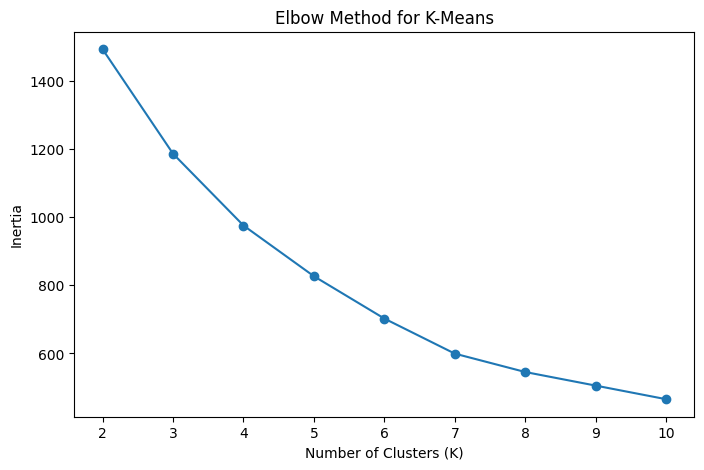


K-Means Cluster Counts:
KMeans_Cluster
0    284
1    120
2     14
Name: count, dtype: int64

K-Means Silhouette Score: 0.4378
Hierarchical Clustering Silhouette Score: 0.3343

Clustering Performance Comparison:


,Clustering Algorithm,Number of Clusters,Silhouette Score
0,K-Means,3,0.4378
1,Hierarchical Clustering,3,0.3343



Original number of features: 5
Reduced number of features: 2


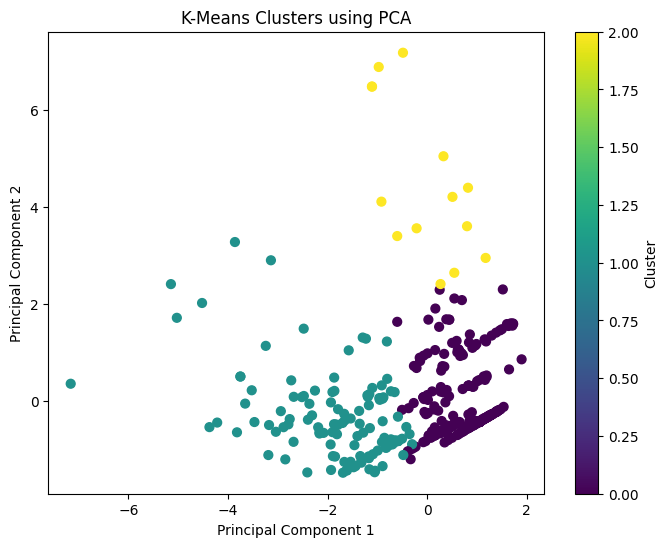

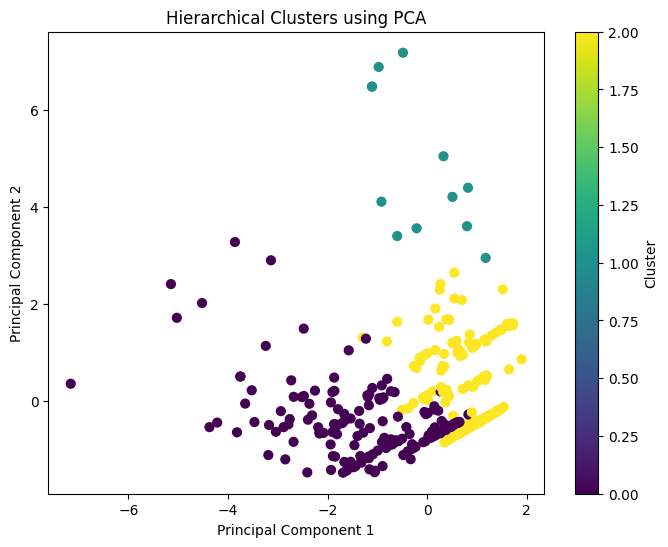


Cross-Validation Scores:
[1. 1. 1. 1. 1.]

Mean 5-Fold Cross-Validation Accuracy: 1.0

Classification Performance:
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


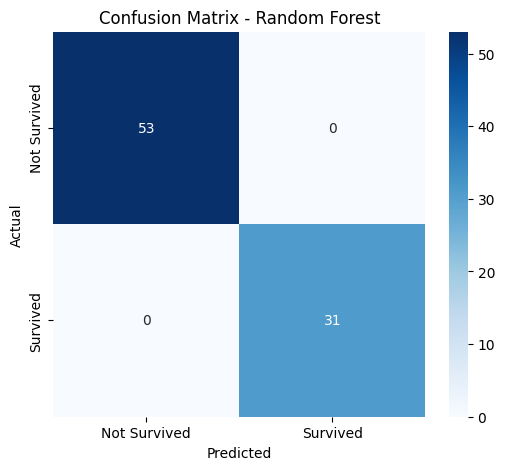


Classification Report:
              precision    recall  f1-score   support

Not Survived       1.00      1.00      1.00        53
    Survived       1.00      1.00      1.00        31

    accuracy                           1.00        84
   macro avg       1.00      1.00      1.00        84
weighted avg       1.00      1.00      1.00        84

ROC-AUC Score: 1.0


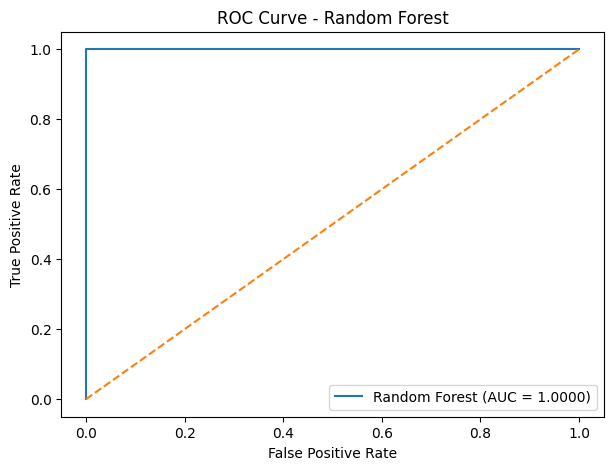


Best Hyperparameters:
{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}

Best Cross-Validation Accuracy: 1.0

FINAL MODEL PERFORMANCE COMPARISON:


,Metric,Random Forest,Tuned Random Forest
0,Accuracy,1.0,1.0
1,Precision,1.0,1.0
2,Recall,1.0,1.0
3,F1 Score,1.0,1.0
4,ROC-AUC,1.0,1.0
5,5-Fold CV Accuracy,1.0,1.0


In [14]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, GridSearchCV

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)



from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

df = df[
    [
        'Survived',
        'Pclass',
        'Sex',
        'Age',
        'SibSp',
        'Parch',
        'Fare',
        'Embarked'
    ]
].copy()

df['Age'] = df['Age'].fillna(df['Age'].median())

df['Fare'] = df['Fare'].fillna(df['Fare'].median())

df['Embarked'] = df['Embarked'].fillna(
    df['Embarked'].mode()[0]
)

df = pd.get_dummies(
    df,
    columns=['Sex', 'Embarked'],
    drop_first=True
)

print("\nPreprocessed Dataset:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())


X_cluster = df[
    [
        'Pclass',
        'Age',
        'SibSp',
        'Parch',
        'Fare'
    ]
].copy()

print("\nFeatures used for clustering:")
print(X_cluster.columns.tolist())


scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

print("\nScaled data:")
print(X_scaled[:5])


inertia = []

for k in range(2, 11):

    kmeans_temp = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans_temp.fit(X_scaled)

    inertia.append(kmeans_temp.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for K-Means')

plt.show()



kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

df['KMeans_Cluster'] = kmeans_labels

print("\nK-Means Cluster Counts:")
print(df['KMeans_Cluster'].value_counts())



kmeans_silhouette = silhouette_score(
    X_scaled,
    kmeans_labels
)

print(
    "\nK-Means Silhouette Score:",
    round(kmeans_silhouette, 4)
)


hierarchical = AgglomerativeClustering(
    n_clusters=3
)

hierarchical_labels = hierarchical.fit_predict(
    X_scaled
)

hierarchical_silhouette = silhouette_score(
    X_scaled,
    hierarchical_labels
)

print(
    "Hierarchical Clustering Silhouette Score:",
    round(hierarchical_silhouette, 4)
)


clustering_results = pd.DataFrame({

    'Clustering Algorithm': [
        'K-Means',
        'Hierarchical Clustering'
    ],

    'Number of Clusters': [
        3,
        3
    ],

    'Silhouette Score': [
        kmeans_silhouette,
        hierarchical_silhouette
    ]

})

clustering_results = clustering_results.round(4)

print("\nClustering Performance Comparison:")
display(clustering_results)



pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(
    "\nOriginal number of features:",
    X_scaled.shape[1]
)

print(
    "Reduced number of features:",
    X_pca.shape[1]
)


plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=40
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.title('K-Means Clusters using PCA')

plt.colorbar(label='Cluster')

plt.show()



plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap='viridis',
    s=40
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.title('Hierarchical Clusters using PCA')

plt.colorbar(label='Cluster')

plt.show()



# Remove clustering column
X = df.drop(
    ['Survived', 'KMeans_Cluster'],
    axis=1
)

y = df['Survived']



X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.2,

    random_state=42,

    stratify=y
)



rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

y_pred = rf_model.predict(X_test)



cv_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print("\nCross-Validation Scores:")
print(cv_scores)

print(
    "\nMean 5-Fold Cross-Validation Accuracy:",
    round(cv_scores.mean(), 4)
)

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

print("\nClassification Performance:")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))



cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title('Confusion Matrix - Random Forest')

plt.show()



print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            'Not Survived',
            'Survived'
        ]
    )
)


y_probability = rf_model.predict_proba(
    X_test
)[:, 1]

roc_auc = roc_auc_score(
    y_test,
    y_probability
)

print(
    "ROC-AUC Score:",
    round(roc_auc, 4)
)



fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f'Random Forest (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve - Random Forest')

plt.legend()

plt.show()


param_grid = {

    'n_estimators': [
        50,
        100,
        200
    ],

    'max_depth': [
        None,
        5,
        10
    ],

    'min_samples_split': [
        2,
        5
    ]
}


grid_search = GridSearchCV(

    RandomForestClassifier(
        random_state=42
    ),

    param_grid,

    cv=5,

    scoring='accuracy',

    n_jobs=-1
)


grid_search.fit(
    X_train,
    y_train
)



print("\nBest Hyperparameters:")

print(
    grid_search.best_params_
)

print(
    "\nBest Cross-Validation Accuracy:",
    round(
        grid_search.best_score_,
        4
    )
)


best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(
    X_test
)

tuned_accuracy = accuracy_score(
    y_test,
    y_pred_tuned
)

tuned_precision = precision_score(
    y_test,
    y_pred_tuned
)

tuned_recall = recall_score(
    y_test,
    y_pred_tuned
)

tuned_f1 = f1_score(
    y_test,
    y_pred_tuned
)

y_probability_tuned = best_model.predict_proba(
    X_test
)[:, 1]

tuned_roc_auc = roc_auc_score(
    y_test,
    y_probability_tuned
)

final_results = pd.DataFrame({

    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score',
        'ROC-AUC',
        '5-Fold CV Accuracy'
    ],

    'Random Forest': [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        cv_scores.mean()
    ],

    'Tuned Random Forest': [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc,
        grid_search.best_score_
    ]

})


final_results = final_results.round(4)

print("\nFINAL MODEL PERFORMANCE COMPARISON:")

display(final_results)
